<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/week6/lesson23/Lesson23_Teaching_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA: Mathematical Sciences for Brain Data**
## Lesson 23 — Coupled ODEs and the Wilson–Cowan Model: Phase Planes, Jacobians and Oscillations

**Course:** MAMBA: Mathematical Sciences for Brain Data\
**Week:** Week 6 — Differential Equations\
**Lesson:** Lesson 23\
**Notebook type:** Teaching notebook

> *"Two variables that push on each other can do what neither can do alone: remember, switch, and oscillate."*

---

### From one variable to two

Lessons 21 and 22 described a neuron with **one** state variable, the membrane potential. Both ended with the same verdict: real neurons need more. Lesson 21's second neuron **sagged** back during a hyperpolarising step, which no single linear ODE can do; Lesson 22's neurons **adapted**, which needs a second, slow variable. And brain circuits are made of interacting **populations**, excitatory and inhibitory, each with its own dynamics.

This lesson treats systems of coupled first-order ODEs, $\dot{\mathbf x} = \mathbf F(\mathbf x)$, with tools that bring together almost the whole course:
1. **state vectors** and coupled rate equations (Lessons 1–4: vectors and matrices);
2. the **phase plane**: direction fields, **nullclines**, **fixed points** and **basins of attraction**;
3. the **Jacobian matrix**, linearisation, and stability from its **eigenvalues** or its **trace and determinant** (Lessons 6, 9 and 14);
4. the **Wilson–Cowan** model of interacting excitatory and inhibitory populations: parameter regimes, bistability, **oscillations** and the intuition behind **bifurcations**;
5. a mini-lab that fits a two-variable model to Lesson 21's sagging neuron, reads off its eigenvalues, and uses it to **predict** a rebound the one-variable model cannot produce.

The Wilson–Cowan parameters are adapted from the Neuromatch Academy tutorial on the model (CC-BY), with time constants rescaled to milliseconds. The recordings are the pyABF sample files (MIT licence) used in Lessons 21–22.

### Import Dependencies

In [1]:
# SETUP CELL
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from scipy.integrate import solve_ivp
from scipy.optimize import fsolve, least_squares
from scipy.linalg import expm

RNG = np.random.default_rng(42)

# The same colourblind-conscious palette and markers as Lessons 1-22.
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
MARKERS = ['o', 's', '^', 'D', 'v', 'P']
LINESTYLES = ['-', '--', ':', '-.']

print("Setup complete.")

Setup complete.


### Interactive and animated plotting tools

As before, each static figure is followed by a **Plotly version** that you can zoom, pan, hover over, and save. Sliders are pre-computed frames, so they work offline and in a static viewer.

In [2]:
# INTERACTIVE/ANIMATION SETUP
import sys
import plotly.io as pio

if 'google.colab' not in sys.modules:
    pio.renderers.default = 'notebook_connected'
pio.templates['plotly_white'].layout.xaxis.showgrid = False
pio.templates['plotly_white'].layout.yaxis.showgrid = False

PLOTLY_CONFIG = {'displaylogo': False, 'responsive': True, 'scrollZoom': True,
                 'toImageButtonOptions': {'format': 'png', 'scale': 2}}

def play_pause_and_slider(labels, prefix, duration=150):
    # Play/Pause buttons and a frame slider, as used in Lessons 1-22.
    buttons = [dict(
        type='buttons', showactive=False, x=0.0, y=-0.12, xanchor='left', yanchor='top',
        buttons=[
            dict(label='Play', method='animate', args=[None, {'frame': {'duration': duration, 'redraw': True}, 'transition': {'duration': 0}, 'fromcurrent': True}]),
            dict(label='Pause', method='animate', args=[[None], {'frame': {'duration': 0, 'redraw': False}, 'mode': 'immediate'}]),
        ],
    )]
    sliders = [dict(
        active=0, currentvalue={'prefix': prefix}, pad={'t': 50},
        steps=[dict(label=str(lab), method='animate', args=[[str(k)], {'mode': 'immediate', 'frame': {'duration': 0, 'redraw': True}, 'transition': {'duration': 0}}])
               for k, lab in enumerate(labels)],
    )]
    return buttons, sliders

print('Interactive plotting and animation tools are ready.')

Interactive plotting and animation tools are ready.


# **Motivation and Retrieval: Why One Variable Is Not Enough**

**Retrieval.**
- Lesson 21: for $\tau\,\dot x = -(x - x_\infty)$, the solution approaches $x_\infty$ **monotonically**. It can never overshoot and come back, because the slope always points towards $x_\infty$ and solutions cannot cross the equilibrium.
- Lesson 6: for a linear system $\mathbf x_{n+1} = A\mathbf x_n$ (discrete time) or $\dot{\mathbf x} = A\mathbf x$ (continuous time), the eigenvalues of $A$ give the timescales, and complex eigenvalues give rotation.

Yet Lesson 21's second neuron, held at −100 pA, fell to −75.9 mV after 90 ms and then **climbed back** by more than 3 mV while the current stayed constant.

**Prediction before running:** add a second, slow variable $w$ that the voltage drives and that pushes back on the voltage. Which of these can the pair $(V, w)$ do: overshoot, oscillate, both, neither? What decides it?

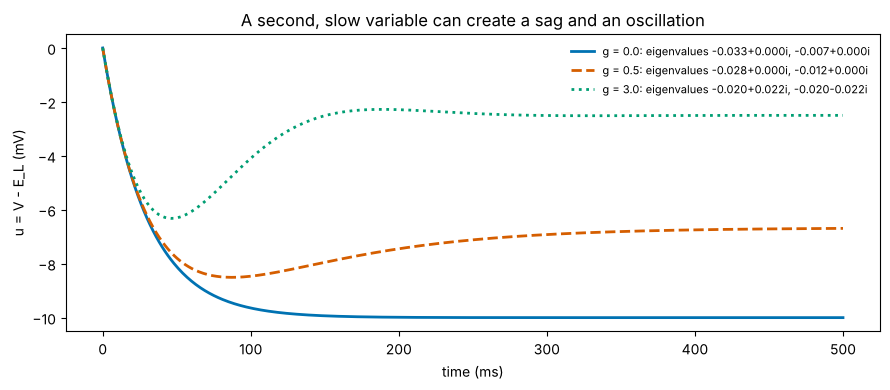

In [3]:
def linear_step(A, b, t):
    # Exact solution of x' = A x + b from x(0) = 0 (Lesson 6's matrix exponential): x(t) = x* + expm(A t)(0 - x*), x* = -A^{-1} b.
    x_star = -np.linalg.solve(A, b)
    return np.array([x_star + expm(A * tt) @ (-x_star) for tt in t])

t = np.linspace(0, 500, 501)                                                # (501,) ms
fig, ax = plt.subplots(figsize=(9, 4))
for k, g in enumerate([0.0, 0.5, 3.0]):
    tau_m, tau_w = 30.0, 150.0                                              # ms
    A = np.array([[-1 / tau_m, -1 / tau_m], [g / tau_w, -1 / tau_w]])      # u = V - E_L (mV), w (mV); u' = (-u - w + R I)/tau_m, w' = (g u - w)/tau_w
    b = np.array([-10.0 / tau_m, 0.0])                                      # R I = -10 mV
    x = linear_step(A, b, t)
    ev = np.linalg.eigvals(A)
    ax.plot(t, x[:, 0], color=PALETTE[k], ls=LINESTYLES[k], lw=2, label=f'g = {g}: eigenvalues ' + ', '.join(f'{e.real:.3f}{e.imag:+.3f}i' for e in ev))
ax.set_xlabel('time (ms)'); ax.set_ylabel('u = V - E_L (mV)'); ax.set_title('A second, slow variable can create a sag and an oscillation')
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

With no coupling ($g = 0$) the voltage relaxes monotonically, as in Lesson 21. With moderate coupling it **sags**: the slow variable builds up and pushes the voltage back. With strong coupling the response **rings**: a damped oscillation, because the eigenvalues have become complex. The eigenvalues of a $2 \times 2$ matrix decide which, and Part 3 shows how to read them from just two numbers, the trace and the determinant.

# **Part 1: State Vectors and Coupled Rate Equations**

A system of $n$ coupled first-order ODEs is one ODE for a **state vector** $\mathbf x(t) \in \mathbb R^n$:

$$\dot{\mathbf x} = \mathbf F(\mathbf x, t), \qquad \mathbf x = \begin{pmatrix} x_1 \\ \vdots \\ x_n \end{pmatrix}, \quad \mathbf F = \begin{pmatrix} F_1(x_1, \dots, x_n, t) \\ \vdots \\ F_n(x_1, \dots, x_n, t)\end{pmatrix}.$$

"Coupled" means that the rate of change of each variable depends on the others. Everything from Lesson 21 carries over component by component: initial-value problems, equilibria ($\mathbf F(\mathbf x^*) = \mathbf 0$), Euler steps $\mathbf x_{n+1} = \mathbf x_n + \Delta t\,\mathbf F(\mathbf x_n, t_n)$, and `solve_ivp`, which already accepts vectors.

**Examples.**
- **Adaptation or sag** (Lesson 22's bonus, the mini-lab here): $(V, w)$, a voltage and a slow current.
- **Excitatory and inhibitory populations** (Wilson–Cowan, Part 4): $(r_E, r_I)$, two firing rates in fractions of their maxima.
- **Hodgkin–Huxley**: $(V, m, h, n)$, voltage plus three gating variables; four coupled nonlinear ODEs.
- **Recurrent neural networks**: $\tau\,\dot{\mathbf r} = -\mathbf r + \phi(W\mathbf r + \mathbf I)$ with a weight matrix $W$ (Lesson 4's affine map plus a nonlinearity, now in continuous time).

**Linear systems** $\dot{\mathbf x} = A\mathbf x + \mathbf b$ are solved by Lesson 6: if $A = P\Lambda P^{-1}$, then in the eigenvector coordinates $\mathbf y = P^{-1}(\mathbf x - \mathbf x^*)$ each mode evolves independently as $y_i(t) = y_i(0)e^{\lambda_i t}$. The solution is a sum of modes $e^{\lambda_i t}\mathbf v_i$; it decays if every $\operatorname{Re}\lambda_i < 0$, and complex pairs $\lambda = \alpha \pm i\omega$ give oscillation at angular frequency $\omega$.

In [4]:
def euler_vec(F, x0, t):
    # Forward Euler for vector ODEs: x[n+1] = x[n] + dt * F(x[n], t[n]). x0: (n_vars,). Returns (len(t), n_vars).
    x = np.empty((len(t), len(x0))); x[0] = x0
    for k in range(len(t) - 1):
        x[k + 1] = x[k] + (t[k + 1] - t[k]) * np.asarray(F(x[k], t[k]))
    return x

# Check: Euler on the linear sag system (g = 3) against the exact matrix-exponential solution, and the modal decomposition.
tau_m, tau_w, g = 30.0, 150.0, 3.0
A = np.array([[-1 / tau_m, -1 / tau_m], [g / tau_w, -1 / tau_w]])
b = np.array([-10.0 / tau_m, 0.0])
t = np.arange(0, 500.01, 0.1)
x_eu = euler_vec(lambda x, tt: A @ x + b, np.zeros(2), t)
x_ex = linear_step(A, b, t[::50])
print(f"max |Euler (dt = 0.1 ms) - exact| = {np.max(np.abs(x_eu[::50] - x_ex)):.4f} mV")
lam, P = np.linalg.eig(A)
print(f"eigenvalues {np.round(lam, 4)} (1/ms): decay time 1/|Re| = {1 / abs(lam[0].real):.1f} ms, oscillation period 2 pi/|Im| = {2 * np.pi / abs(lam[0].imag):.0f} ms")
x_star = -np.linalg.solve(A, b)
c = np.linalg.solve(P, -x_star)                                              # modal coordinates of the initial deviation
x_modes = np.real(np.array([x_star + P @ (c * np.exp(lam * tt)) for tt in t[::50]]))
print(f"max |modal solution - exact| = {np.max(np.abs(x_modes - x_ex)):.1e} mV")

max |Euler (dt = 0.1 ms) - exact| = 0.0090 mV
eigenvalues [-0.02+0.0221j -0.02-0.0221j] (1/ms): decay time 1/|Re| = 50.0 ms, oscillation period 2 pi/|Im| = 284 ms
max |modal solution - exact| = 5.6e-14 mV


# **Part 2: The Phase Plane — Direction Fields, Nullclines, Fixed Points and Basins**

For two variables $(x, y)$ the state is a point in the **phase plane**, and the ODE assigns an arrow $(\dot x, \dot y)$ to every point: the **direction field** (Lesson 21's slope field, now in two dimensions, with time hidden). A solution is a **trajectory**, a curve that follows the arrows.

- The **$x$-nullcline** is the curve where $\dot x = 0$: trajectories cross it vertically. The **$y$-nullcline**, where $\dot y = 0$, is crossed horizontally.
- **Fixed points** (equilibria) are where the nullclines intersect: both rates are zero.
- The **basin of attraction** of a stable fixed point is the set of initial states that end up there. Basins are separated by the **stable manifold** of a saddle point, the 2D version of Lesson 21's unstable equilibrium on the phase line.

**Example: two populations that excite themselves and inhibit each other**, a minimal model of a binary decision (two choices compete; the first to win suppresses the other):
$$\tau\,\dot r_1 = -r_1 + F(w_s r_1 - w_c r_2 + I_1), \qquad \tau\,\dot r_2 = -r_2 + F(w_s r_2 - w_c r_1 + I_2),$$
with the sigmoid $F(u) = 1/(1 + e^{-(u - 0.5)/0.1})$ (rates as fractions of their maxima).

fixed point r = (0.208, 0.208): eigenvalues [ 0.164+0.j -0.166+0.j] 1/ms -> saddle
fixed point r = (0.000, 0.996): eigenvalues [-0.1   +0.j -0.0975+0.j] 1/ms -> stable
fixed point r = (0.996, 0.000): eigenvalues [-0.0975+0.j -0.1   +0.j] 1/ms -> stable


basins: choice 1 wins from 49.2% of starts, choice 2 from 49.2%, undecided 1.6%


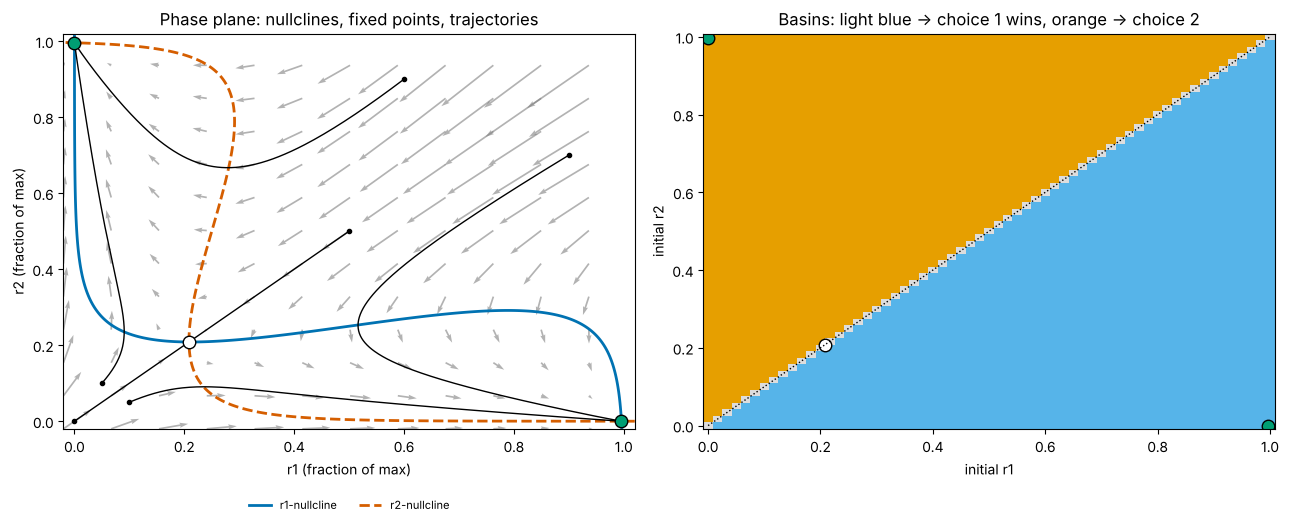

In [5]:
def F_sig(u, theta=0.5, k=0.1):
    return 1 / (1 + np.exp(-(u - theta) / k))

w_s, w_c, I1, I2, tau = 0.6, 1.0, 0.45, 0.45, 10.0                          # self-excitation, cross-inhibition, inputs, ms
def F_dec(x, t=0):
    r1, r2 = x[0], x[1]
    return np.array([(-r1 + F_sig(w_s * r1 - w_c * r2 + I1)) / tau, (-r2 + F_sig(w_s * r2 - w_c * r1 + I2)) / tau])

def find_fixed_points(F, guesses, tol=1e-6):
    pts = []
    for g0 in guesses:
        s, info, ier, _ = fsolve(lambda x: F(x), g0, full_output=True)
        if ier == 1 and np.max(np.abs(F(s))) < 1e-9 and not any(np.allclose(s, p_, atol=tol * 100) for p_ in pts):
            pts.append(s)
    return pts

def jacobian(F, x, h=1e-6):
    # Numerical Jacobian J[i, j] = dF_i/dx_j by centred differences (Lesson 9, Lesson 14).
    x = np.asarray(x, float); J = np.zeros((len(x), len(x)))
    for j in range(len(x)):
        e = np.zeros(len(x)); e[j] = h
        J[:, j] = (F(x + e) - F(x - e)) / (2 * h)
    return J

grid_guess = [np.array([a, b_]) for a in np.linspace(0, 1, 6) for b_ in np.linspace(0, 1, 6)]
fps_dec = find_fixed_points(F_dec, grid_guess)
for p_ in fps_dec:
    ev = np.linalg.eigvals(jacobian(F_dec, p_))
    kind = 'stable' if np.all(ev.real < 0) else ('saddle' if np.prod(np.sign(ev.real)) < 0 else 'unstable')
    print(f"fixed point r = ({p_[0]:.3f}, {p_[1]:.3f}): eigenvalues {np.round(ev, 4)} 1/ms -> {kind}")

# Direction field, nullclines (zero contours of each rate), fixed points, trajectories and basins (vectorised Euler over a grid of starts).
r = np.linspace(-0.02, 1.02, 300); R1, R2 = np.meshgrid(r, r)
D1 = -R1 + F_sig(w_s * R1 - w_c * R2 + I1); D2 = -R2 + F_sig(w_s * R2 - w_c * R1 + I2)
starts = np.linspace(0, 1, 61); S1, S2 = np.meshgrid(starts, starts)      # (61, 61) initial conditions
X1, X2 = S1.copy(), S2.copy()
for _ in range(3000):                                                       # 300 ms of Euler with dt = 0.1 ms, all starts at once
    X1, X2 = X1 + 0.1 / tau * (-X1 + F_sig(w_s * X1 - w_c * X2 + I1)), X2 + 0.1 / tau * (-X2 + F_sig(w_s * X2 - w_c * X1 + I2))
winner = np.where(X1 > X2 + 0.1, 1, np.where(X2 > X1 + 0.1, 2, 0))          # (61, 61): which choice won
print(f"basins: choice 1 wins from {np.mean(winner == 1):.1%} of starts, choice 2 from {np.mean(winner == 2):.1%}, undecided {np.mean(winner == 0):.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
ax = axes[0]
q = slice(None, None, 25)
ax.quiver(R1[q, q], R2[q, q], D1[q, q], D2[q, q], color='grey', alpha=0.6, angles='xy', width=0.003)
ax.contour(R1, R2, D1, levels=[0], colors=[PALETTE[0]], linewidths=2)
ax.contour(R1, R2, D2, levels=[0], colors=[PALETTE[1]], linewidths=2, linestyles='--')
for x0 in [[0.1, 0.05], [0.05, 0.1], [0.9, 0.7], [0.6, 0.9], [0.0, 0.0], [0.5, 0.5]]:
    xs = euler_vec(F_dec, np.array(x0, float), np.arange(0, 300, 0.1))
    ax.plot(xs[:, 0], xs[:, 1], color='black', lw=1); ax.plot(*x0, 'k.', ms=6)
for p_ in fps_dec:
    ev = np.linalg.eigvals(jacobian(F_dec, p_))
    ax.plot(*p_, 'o', ms=9, color=PALETTE[2] if np.all(ev.real < 0) else 'white', markeredgecolor='black', zorder=4)
ax.plot([], [], color=PALETTE[0], lw=2, label='r1-nullcline'); ax.plot([], [], color=PALETTE[1], lw=2, ls='--', label='r2-nullcline')
ax.set_xlabel('r1 (fraction of max)'); ax.set_ylabel('r2 (fraction of max)'); ax.set_title('Phase plane: nullclines, fixed points, trajectories')
ax.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2); ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
ax = axes[1]
ax.pcolormesh(S1, S2, winner, cmap=plt.matplotlib.colors.ListedColormap(['#dddddd', PALETTE[5], PALETTE[4]]), shading='auto', vmin=0, vmax=2)
for p_ in fps_dec:
    ev = np.linalg.eigvals(jacobian(F_dec, p_))
    ax.plot(*p_, 'o', ms=9, color=PALETTE[2] if np.all(ev.real < 0) else 'white', markeredgecolor='black')
ax.plot([0, 1], [0, 1], ':', color='black', lw=1)
ax.set_xlabel('initial r1'); ax.set_ylabel('initial r2'); ax.set_title('Basins: light blue -> choice 1 wins, orange -> choice 2')
plt.tight_layout(); plt.show()

- The nullclines cross three times: two **stable** fixed points (one population high, the other low: a decision) and a **saddle** on the diagonal, where both are moderately active.
- Trajectories are attracted to the diagonal and then pushed away from the saddle towards one of the decisions. The diagonal ($r_1 = r_2$) is the boundary between the two **basins**: whichever population starts ahead wins. With equal inputs the basins are mirror images; a slightly larger $I_1$ moves the boundary and biases the decision.
- This is Lesson 21's bistable phase line in two dimensions, and the core of attractor models of decision making and working memory.

# **Part 3: The Jacobian, Linearisation and Stability**

Near a fixed point $\mathbf x^*$, write $\mathbf x = \mathbf x^* + \boldsymbol\delta$. By the multivariable Taylor expansion (Lesson 14), $\mathbf F(\mathbf x^* + \boldsymbol\delta) \approx \mathbf F(\mathbf x^*) + J\boldsymbol\delta = J\boldsymbol\delta$, where the **Jacobian**

$$J = \begin{pmatrix} \partial F_1/\partial x_1 & \partial F_1/\partial x_2 \\ \partial F_2/\partial x_1 & \partial F_2/\partial x_2 \end{pmatrix}_{\mathbf x^*}$$

is the matrix of partial derivatives (each row is the gradient of one rate). Small deviations obey the **linear** system $\dot{\boldsymbol\delta} = J\boldsymbol\delta$, so Part 1 applies: the fixed point is stable if all eigenvalues of $J$ have negative real part. (This linearisation is reliable unless some eigenvalue has zero real part: the borderline case where bifurcations happen.)

**Trace and determinant.** For a $2 \times 2$ matrix, the eigenvalues solve $\lambda^2 - \tau\lambda + \Delta = 0$ with $\tau = \operatorname{tr} J = \lambda_1 + \lambda_2$ and $\Delta = \det J = \lambda_1\lambda_2$:

$$\lambda_{1,2} = \frac{\tau \pm \sqrt{\tau^2 - 4\Delta}}{2}.$$

| Condition | Eigenvalues | Fixed point |
|---|---|---|
| $\Delta < 0$ | real, opposite signs | **saddle** (unstable) |
| $\Delta > 0$, $\tau < 0$, $\tau^2 > 4\Delta$ | real, both negative | **stable node** |
| $\Delta > 0$, $\tau < 0$, $\tau^2 < 4\Delta$ | complex, negative real part | **stable focus** (damped oscillation) |
| $\Delta > 0$, $\tau > 0$ | positive real parts | **unstable** node or focus |
| $\Delta > 0$, $\tau = 0$ | purely imaginary | **centre**: the boundary where oscillations can be born |

sag system, g = 0.5   : trace -0.0400, det +0.00033, eigenvalues [-0.0282+0.j -0.0118+0.j] -> stable node
sag system, g = 3     : trace -0.0400, det +0.00089, eigenvalues [-0.02+0.0221j -0.02-0.0221j] -> stable focus
decision saddle       : trace -0.0020, det -0.02723, eigenvalues [ 0.164+0.j -0.166+0.j] -> saddle
rotation              : trace +0.0000, det +0.00160, eigenvalues [0.+0.04j 0.-0.04j] -> centre
growing focus         : trace +0.0200, det +0.00170, eigenvalues [0.01+0.04j 0.01-0.04j] -> unstable focus



kick from the stable decision state: measured decay rate -0.0999 1/ms;  slowest eigenvalue -0.0975 1/ms


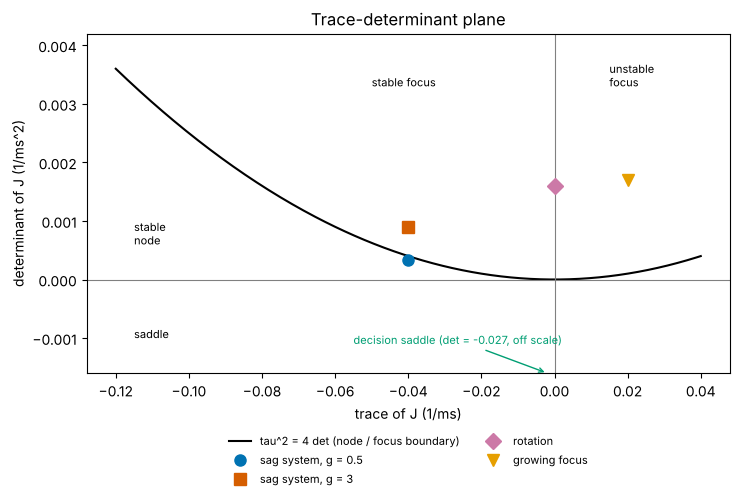

In [6]:
def classify(J):
    tr, det = np.trace(J), np.linalg.det(J); disc = tr**2 - 4 * det
    if det < 0:
        return 'saddle'
    if abs(tr) < 1e-12:
        return 'centre'
    kind = 'node' if disc >= 0 else 'focus'
    return ('stable ' if tr < 0 else 'unstable ') + kind

examples = {'sag system, g = 0.5': np.array([[-1 / 30, -1 / 30], [0.5 / 150, -1 / 150]]),
            'sag system, g = 3': np.array([[-1 / 30, -1 / 30], [3 / 150, -1 / 150]]),
            'decision saddle': jacobian(F_dec, fps_dec[[np.isclose(p_[0], p_[1], atol=1e-3) for p_ in fps_dec].index(True)]),
            'rotation': np.array([[0.0, -0.04], [0.04, 0.0]]),
            'growing focus': np.array([[0.01, -0.04], [0.04, 0.01]])}
for name, J in examples.items():
    ev = np.linalg.eigvals(J)
    print(f"{name:<22}: trace {np.trace(J):+.4f}, det {np.linalg.det(J):+.5f}, eigenvalues {np.round(ev, 4)} -> {classify(J)}")

# Linearisation check at the stable decision state: a small kick decays at the rate of the slowest eigenvalue.
p_stab = [p_ for p_ in fps_dec if p_[0] > p_[1] + 0.1][0]
ev_s = np.linalg.eigvals(jacobian(F_dec, p_stab))
xs = euler_vec(F_dec, p_stab + np.array([0.01, 0.01]), np.arange(0, 300, 0.01))
dist = np.linalg.norm(xs - p_stab, axis=1)
slope = np.polyfit(np.arange(0, 300, 0.01)[10000:25000], np.log(dist[10000:25000]), 1)[0]
print(f"\nkick from the stable decision state: measured decay rate {slope:.4f} 1/ms;  slowest eigenvalue {max(ev_s.real):.4f} 1/ms")

fig, ax = plt.subplots(figsize=(7.5, 5.2))
trs = np.linspace(-0.12, 0.04, 300)
ax.plot(trs, trs**2 / 4, color='black', lw=1.5, label='tau^2 = 4 det (node / focus boundary)')
ax.axhline(0, color='grey', lw=0.8); ax.axvline(0, color='grey', lw=0.8)
for k, (name, J) in enumerate(examples.items()):
    if name == 'decision saddle':                                                # far below the plotted range: mark it with an arrow
        ax.annotate(f'decision saddle (det = {np.linalg.det(J):.3f}, off scale)', xy=(np.trace(J), -0.0016), xytext=(-0.055, -0.0011),
                    fontsize=8, color=PALETTE[k], arrowprops=dict(arrowstyle='->', color=PALETTE[k]))
        continue
    ax.plot(np.trace(J), np.linalg.det(J), MARKERS[k], ms=8, color=PALETTE[k], label=name)
ax.text(-0.115, 0.0006, 'stable\nnode', fontsize=8); ax.text(-0.05, 0.0033, 'stable focus', fontsize=8)
ax.text(0.015, 0.0033, 'unstable\nfocus', fontsize=8); ax.text(-0.115, -0.0010, 'saddle', fontsize=8)
ax.set_xlabel('trace of J (1/ms)'); ax.set_ylabel('determinant of J (1/ms^2)'); ax.set_title('Trace-determinant plane')
ax.set_ylim(-0.0016, 0.0042)
ax.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2); plt.tight_layout(); plt.show()

- The classification needs only two numbers: the **determinant** (product of the eigenvalues) separates saddles from everything else, the **trace** (their sum) separates stable from unstable, and the parabola $\tau^2 = 4\Delta$ separates monotone (node) from oscillating (focus) behaviour.
- The sag system moves from a stable node ($g = 0.5$: overshoot without oscillation) to a stable focus ($g = 3$: damped ringing) as the coupling grows. The decision model's symmetric state is a saddle ($\Delta < 0$).
- The linearisation is quantitative: a small kick away from a stable state decays at the rate given by the Jacobian's slowest eigenvalue.

**Moving through the plane is how behaviour changes.** As a parameter changes, $(\tau, \Delta)$ moves. Crossing $\Delta = 0$ creates or destroys fixed points (a saddle-node bifurcation: how the decision model gains its two stable states as self-excitation grows). Crossing $\tau = 0$ with $\Delta > 0$ turns a stable focus into an unstable one: damped oscillations become sustained ones, a **Hopf bifurcation**. Part 4 shows both in a cortical circuit model.

# **Part 4: The Wilson–Cowan Model**

Wilson and Cowan (1972) described a cortical column by the mean activity of an **excitatory** population $r_E$ and an **inhibitory** population $r_I$ (fractions of their maximal rates):

$$\tau_E\,\dot r_E = -r_E + F_E\big(w_{EE}r_E - w_{EI}r_I + P\big), \qquad \tau_I\,\dot r_I = -r_I + F_I\big(w_{IE}r_E - w_{II}r_I + Q\big),$$

with sigmoid gain functions $F(x) = \dfrac{1}{1 + e^{-a(x - \theta)}} - \dfrac{1}{1 + e^{a\theta}}$ (shifted so that $F(0) = 0$). Excitation excites both populations; inhibition inhibits both. $P$ and $Q$ are external drives. Each term is a piece of earlier lessons: a weighted sum (Lesson 2), a sigmoid (Lesson 8), a relaxation with a time constant (Lesson 21), and noise-smoothed thresholds (Lesson 22's F–I curves under noise).

**Parameters** (adapted from the Neuromatch Academy Wilson–Cowan tutorial, CC-BY, with $\tau_E = 10$ ms and $\tau_I = 20$ ms): $a_E = 1.2$, $\theta_E = 2.8$, $a_I = 1$, $\theta_I = 4$. Two weight sets give two regimes:
- **Set A** ($w_{EE} = 9$, $w_{EI} = 4$, $w_{IE} = 13$, $w_{II} = 11$, $P = 0$): strong recurrent excitation.
- **Set B** ($w_{EE} = 6.4$, $w_{EI} = 4.8$, $w_{IE} = 6$, $w_{II} = 1.2$, $P = 0.9$): strong, slow inhibition.

Set A: bistable: fixed point (rE, rI) = (0.000, 0.000), eigenvalues [-0.0623+0.0131j -0.0623-0.0131j] 1/ms -> stable focus
Set A: bistable: fixed point (rE, rI) = (0.337, 0.168), eigenvalues [ 0.1057+0.j -0.0873+0.j] 1/ms -> saddle
Set A: bistable: fixed point (rE, rI) = (0.938, 0.672), eigenvalues [-0.096 +0.j -0.1422+0.j] 1/ms -> stable node


Set B: oscillating: fixed point (rE, rI) = (0.618, 0.320), eigenvalues [0.0054+0.0635j 0.0054-0.0635j] 1/ms -> unstable focus


Set B: oscillating: sustained oscillation, rE between 0.139 and 0.799, period 162.5 ms (6.2 Hz)


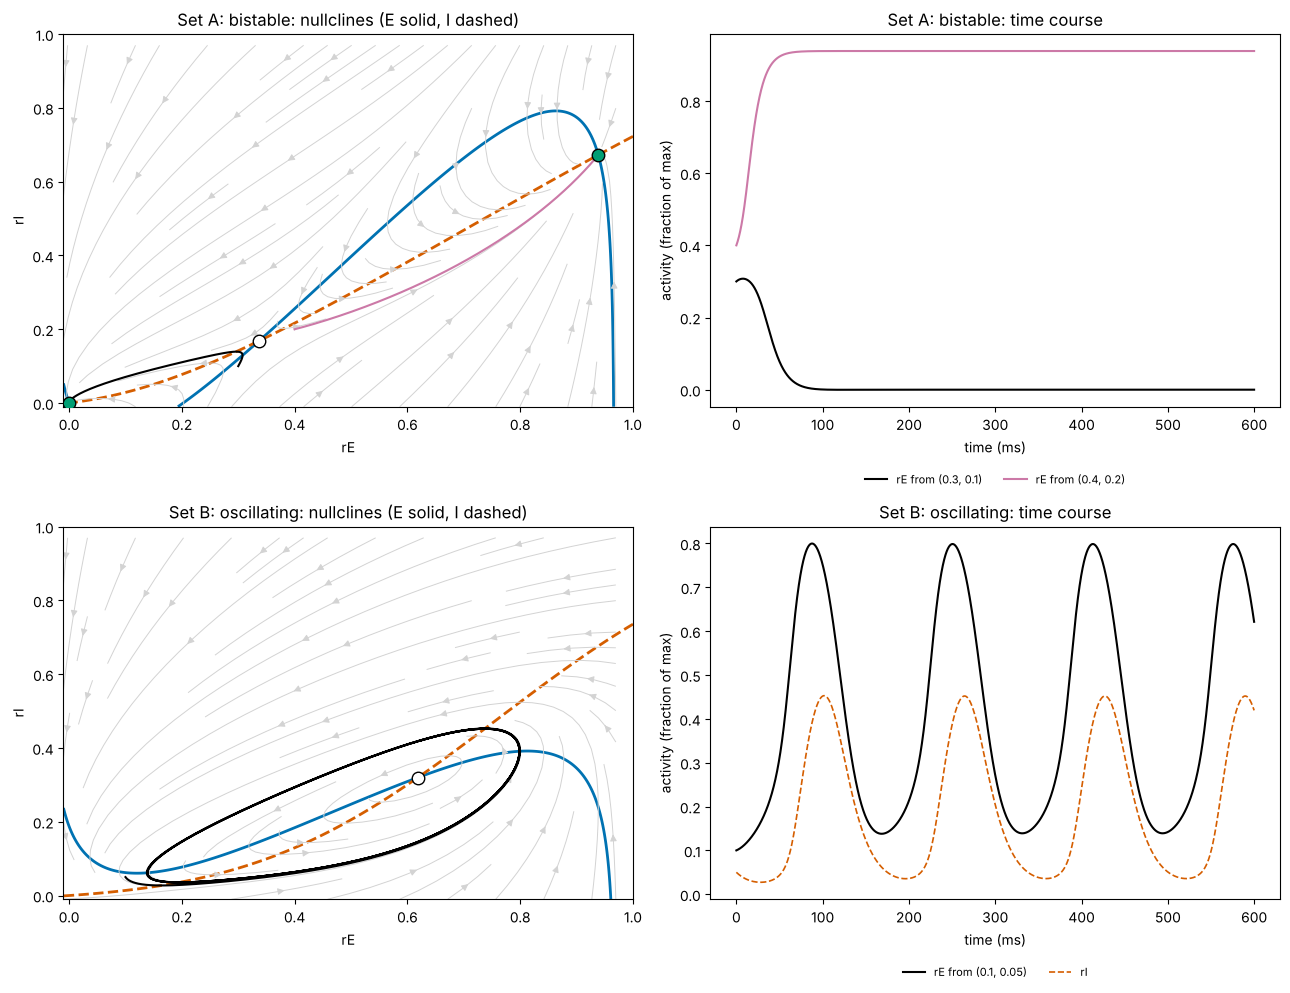

In [7]:
def F_wc(x, a, theta):
    return 1 / (1 + np.exp(-a * (x - theta))) - 1 / (1 + np.exp(a * theta))

WC_BASE = dict(tE=10.0, tI=20.0, aE=1.2, thE=2.8, aI=1.0, thI=4.0, Q=0.0)
SET_A = dict(WC_BASE, wEE=9.0, wEI=4.0, wIE=13.0, wII=11.0, P=0.0)
SET_B = dict(WC_BASE, wEE=6.4, wEI=4.8, wIE=6.0, wII=1.2, P=0.9)

def wc_rhs(x, p):
    rE, rI = x[0], x[1]
    return np.array([(-rE + F_wc(p['wEE'] * rE - p['wEI'] * rI + p['P'], p['aE'], p['thE'])) / p['tE'],
                     (-rI + F_wc(p['wIE'] * rE - p['wII'] * rI + p['Q'], p['aI'], p['thI'])) / p['tI']])

def wc_simulate(p, x0, T=1000.0, dt=0.1):
    return solve_ivp(lambda t, x: wc_rhs(x, p), [0, T], x0, t_eval=np.arange(0, T, dt), max_step=0.5, rtol=1e-8, atol=1e-10)

guesses = [np.array([a, b_]) for a in np.linspace(0, 1, 8) for b_ in np.linspace(0, 1, 8)]
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for row, (name, p) in enumerate([('Set A: bistable', SET_A), ('Set B: oscillating', SET_B)]):
    fps_wc = find_fixed_points(lambda x: wc_rhs(x, p), guesses)
    for f_ in fps_wc:
        J = jacobian(lambda x: wc_rhs(x, p), f_)
        print(f"{name}: fixed point (rE, rI) = ({f_[0]:.3f}, {f_[1]:.3f}), eigenvalues {np.round(np.linalg.eigvals(J), 4)} 1/ms -> {classify(J)}")
    rr = np.linspace(-0.01, 1.0, 300); RE, RI = np.meshgrid(rr, rr)
    DE = -RE + F_wc(p['wEE'] * RE - p['wEI'] * RI + p['P'], p['aE'], p['thE'])
    DI = -RI + F_wc(p['wIE'] * RE - p['wII'] * RI + p['Q'], p['aI'], p['thI'])
    ax = axes[row, 0]
    ax.contour(RE, RI, DE, levels=[0], colors=[PALETTE[0]], linewidths=2)
    ax.contour(RE, RI, DI, levels=[0], colors=[PALETTE[1]], linewidths=2, linestyles='--')
    ax.streamplot(RE[::10, ::10], RI[::10, ::10], DE[::10, ::10] / p['tE'], DI[::10, ::10] / p['tI'], color='lightgrey', density=0.8, linewidth=0.7)
    inits = [[0.3, 0.1], [0.4, 0.2]] if row == 0 else [[0.1, 0.05]]
    for k, x0 in enumerate(inits):
        sol = wc_simulate(p, x0, T=600)
        ax.plot(sol.y[0], sol.y[1], color=['black', PALETTE[3]][k], lw=1.5)
        axes[row, 1].plot(sol.t, sol.y[0], color=['black', PALETTE[3]][k], lw=1.5, label=f'rE from ({x0[0]}, {x0[1]})')
        if row == 1:
            axes[row, 1].plot(sol.t, sol.y[1], color=PALETTE[1], lw=1.2, ls='--', label='rI')
            late = sol.t > 300; E_ = sol.y[0][late]; tt_ = sol.t[late]
            pk = np.where((E_[1:-1] > E_[:-2]) & (E_[1:-1] > E_[2:]))[0] + 1
            print(f"{name}: sustained oscillation, rE between {E_.min():.3f} and {E_.max():.3f}, period {np.mean(np.diff(tt_[pk])):.1f} ms ({1000 / np.mean(np.diff(tt_[pk])):.1f} Hz)")
    for f_ in fps_wc:
        ev = np.linalg.eigvals(jacobian(lambda x: wc_rhs(x, p), f_))
        ax.plot(*f_, 'o', ms=9, color=PALETTE[2] if np.all(ev.real < 0) else 'white', markeredgecolor='black', zorder=4)
    ax.set_xlim(-0.01, 1.0); ax.set_ylim(-0.01, 1.0)
    ax.set_xlabel('rE'); ax.set_ylabel('rI'); ax.set_title(f'{name}: nullclines (E solid, I dashed)')
    axes[row, 1].set_xlabel('time (ms)'); axes[row, 1].set_ylabel('activity (fraction of max)'); axes[row, 1].set_title(f'{name}: time course')
    axes[row, 1].legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3)
plt.tight_layout(); plt.show()

- **Set A (bistable).** The nullclines cross three times: a stable **low-activity** state (near zero), a stable **high-activity** state, and a saddle between them. Two nearby initial conditions end in different states. Strong recurrent excitation lets the circuit hold a "memory" of a transient input: persistent activity.
- **Set B (oscillating).** The nullclines cross once, at a fixed point whose eigenvalues are a complex pair with **positive** real part: an unstable focus. Trajectories spiral away from it, but cannot escape the bounded square (the sigmoids cap the rates), and settle on a closed orbit, a **limit cycle**: a sustained E–I oscillation. Excitation rises, recruits inhibition with a delay (slower $\tau_I$), inhibition shuts excitation down, then decays, and the cycle repeats. This is the mechanism proposed for many cortical rhythms (the **PING** mechanism for gamma oscillations, with faster time constants than here).

**Bifurcation intuition.** In Set B, change the external drive $P$ to the excitatory population and follow the fixed point's eigenvalues. Where their real part crosses zero, a stable focus becomes unstable and a limit cycle is born or dies: a **Hopf bifurcation**. Below we sweep $P$ and record the range of $r_E$ after transients.

sustained oscillations (from rE = 0.1, rI = 0.05) for P from 0.75 to 1.00; frequency 3.5-10.4 Hz
upper fixed point: real part of its eigenvalues changes from positive to non-positive between P = 0.95 and 1.00 (Hopf)
three fixed points (quiet state, saddle, unstable focus) for P = [0.65, 0.7]; quiet state exists up to P = 0.70


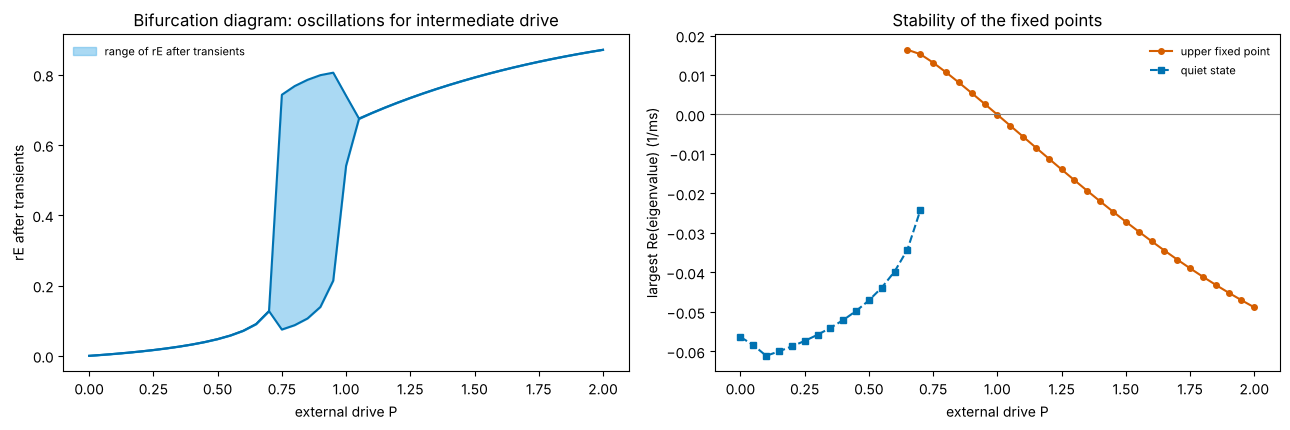

In [8]:
P_list = np.round(np.arange(0.0, 2.01, 0.05), 2)
amp_lo, amp_hi, re_up, re_low, freq, n_fp = [], [], [], [], [], []
for P_ in P_list:
    p = dict(SET_B, P=P_)
    sol = wc_simulate(p, [0.1, 0.05], T=3000)
    late = sol.t > 2000; E_ = sol.y[0][late]; tt_ = sol.t[late]
    amp_lo.append(E_.min()); amp_hi.append(E_.max())
    pk = np.where((E_[1:-1] > E_[:-2]) & (E_[1:-1] > E_[2:]))[0] + 1
    freq.append(1000 / np.mean(np.diff(tt_[pk])) if E_.max() - E_.min() > 0.01 and len(pk) > 2 else np.nan)
    fp_ = sorted(find_fixed_points(lambda x: wc_rhs(x, p), guesses), key=lambda f_: f_[0])
    re_up.append(np.linalg.eigvals(jacobian(lambda x: wc_rhs(x, p), fp_[-1])).real.max() if fp_[-1][0] >= 0.2 else np.nan)   # the upper (high-rE) fixed point, once it exists
    ev_low = np.linalg.eigvals(jacobian(lambda x: wc_rhs(x, p), fp_[0])).real.max()
    re_low.append(ev_low if fp_[0][0] < 0.2 else np.nan)                                            # the quiet state (rE < 0.2), while it exists
    n_fp.append(len(fp_))
amp_lo, amp_hi, re_up, re_low, freq = map(np.array, (amp_lo, amp_hi, re_up, re_low, freq))
osc = amp_hi - amp_lo > 0.01
print(f"sustained oscillations (from rE = 0.1, rI = 0.05) for P from {P_list[osc].min():.2f} to {P_list[osc].max():.2f}; frequency {np.nanmin(freq):.1f}-{np.nanmax(freq):.1f} Hz")
hopf = P_list[np.where((re_up[:-1] > 0) & (re_up[1:] <= 0))[0]]   # comparisons with nan are False
print(f"upper fixed point: real part of its eigenvalues changes from positive to non-positive between P = {hopf[0]:.2f} and {hopf[0] + 0.05:.2f} (Hopf)")
print(f"three fixed points (quiet state, saddle, unstable focus) for P = {P_list[np.array(n_fp) == 3].tolist()}; quiet state exists up to P = {P_list[np.isfinite(re_low)].max():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].fill_between(P_list, amp_lo, amp_hi, color=PALETTE[5], alpha=0.5, label='range of rE after transients')
axes[0].plot(P_list, amp_lo, color=PALETTE[0], lw=1.5); axes[0].plot(P_list, amp_hi, color=PALETTE[0], lw=1.5)
axes[0].set_xlabel('external drive P'); axes[0].set_ylabel('rE after transients'); axes[0].set_title('Bifurcation diagram: oscillations for intermediate drive')
axes[0].legend(frameon=False, fontsize=8, loc='upper left')
axes[1].plot(P_list, re_up, 'o-', color=PALETTE[1], lw=1.5, ms=4, label='upper fixed point')
axes[1].plot(P_list, re_low, 's--', color=PALETTE[0], lw=1.5, ms=4, label='quiet state')
axes[1].axhline(0, color='grey', lw=0.8)
axes[1].set_xlabel('external drive P'); axes[1].set_ylabel('largest Re(eigenvalue) (1/ms)'); axes[1].set_title('Stability of the fixed points')
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

For weak drive the circuit sits at a quiet stable state; for intermediate drive it oscillates; for strong drive it settles to a high, stable, non-oscillating state. The two edges are different kinds of event:
- **Upper edge (Hopf).** The upper fixed point is an unstable focus throughout the oscillating range; near $P = 1$ the real part of its eigenvalues crosses zero, it becomes a stable focus, and the oscillation amplitude shrinks towards zero.
- **Lower edge (saddle-node).** Around $P = 0.65$–$0.70$ there are three fixed points: the quiet stable state, a saddle and the unstable focus. Just above 0.70 the quiet state and the saddle collide and vanish (the excitatory nullcline's fold slides past the inhibitory nullcline), and the trajectory has nowhere to go but onto a large limit cycle: the oscillation appears abruptly, at full amplitude. The details of bifurcation theory are beyond this course; the intuition to keep is that **qualitative behaviour changes where eigenvalues cross zero**, and that you can find those places by tracking the Jacobian as a parameter changes.

#### Interactive version: drive and the E–I phase plane

In [9]:
P_frames = [0.4, 0.7, 0.8, 0.9, 1.0, 1.1, 1.4, 2.0]
def wc_traj(P_):
    sol = wc_simulate(dict(SET_B, P=P_), [0.1, 0.05], T=600, dt=0.5)
    return sol.y[0], sol.y[1]
E0_, I0_ = wc_traj(P_frames[0])
fig_w = go.Figure([go.Scatter(x=np.round(E0_, 4), y=np.round(I0_, 4), mode='lines', line=dict(color=PALETTE[0], width=2), name='trajectory from (0.1, 0.05)')])
frames = []
for i, P_ in enumerate(P_frames):
    E_, I_ = wc_traj(P_)
    p = dict(SET_B, P=P_); fp_ = find_fixed_points(lambda x: wc_rhs(x, p), guesses)
    lab = ', '.join(classify(jacobian(lambda x: wc_rhs(x, p), f_)) for f_ in fp_)
    frames.append(go.Frame(name=str(i), data=[go.Scatter(x=np.round(E_, 4), y=np.round(I_, 4))],
                           layout=go.Layout(title=f'P = {P_}: fixed point(s): {lab}')))
fig_w.frames = frames
buttons, sliders = play_pause_and_slider(P_frames, prefix='P = ', duration=900)
fig_w.update_layout(title=frames[0].layout.title.text, xaxis=dict(title='rE', range=[0, 1]), yaxis=dict(title='rI', range=[0, 0.8]),
                    template='plotly_white', width=750, height=550, updatemenus=buttons, sliders=sliders)
fig_w.show(config=PLOTLY_CONFIG)

# **Part 5: Mini-Lab — A Two-Variable Model of a Sagging Neuron**

**Data.** Lesson 21's second neuron (`171116sh_0018.abf`, pyABF sample files, MIT licence; cell type undocumented), 17 sweeps at 10 kHz. Every sweep holds −100 pA from 1.147 to 1.647 s; sweep 4 then injects 0 pA, so it shows what happens **after** the hyperpolarisation ends.

- `V` (17, 30000): membrane potential, mV. `I` (17, 30000): injected current, pA. `t` (30000,): time, s.

Lesson 21 found that a single exponential cannot describe this neuron (the fitted $\tau_m$ ranged from 17 to 35 ms depending on the window) because of a 3 mV sag.

**Model.** With $u = V - E_L$ (mV) and a slow variable $w$ (mV), standing for a current such as $I_h$ that is activated by hyperpolarisation and depolarises the cell:
$$\tau_m\,\dot u = -u - w + R_m I(t), \qquad \tau_w\,\dot w = -w + g\,u.$$
When $u < 0$, $w$ slowly becomes negative and $-w$ pushes $u$ back up: the sag. The Jacobian is constant:
$$J = \begin{pmatrix} -1/\tau_m & -1/\tau_m \\ g/\tau_w & -1/\tau_w \end{pmatrix}, \qquad \operatorname{tr}J = -\Big(\frac1{\tau_m} + \frac1{\tau_w}\Big), \quad \det J = \frac{1 + g}{\tau_m\tau_w}.$$

**Questions.**
1. Fit $(\tau_m, R_m, \tau_w, g)$ to the mean response to −100 pA. Is it better than one exponential?
2. What are the eigenvalues and the type of the fixed point? Is this neuron a resonator?
3. **Prediction:** what should happen when the current is switched off? Test it on sweep 4.

In [10]:
import os, urllib.request
PATCH_FILE = 'patch_171116sh_0018_steps.npz'
for cand in [PATCH_FILE, os.path.join('..', '..', 'data', PATCH_FILE)]:
    if os.path.exists(cand):
        patch_path = cand; break
else:
    urllib.request.urlretrieve('https://raw.githubusercontent.com/peter-adepoju/math-neuro-ml/e8996ac071a2a16c48d5b544ec3470816eecf49f/data/' + PATCH_FILE, PATCH_FILE)
    patch_path = PATCH_FILE
dp = np.load(patch_path)
V = dp['v_cmV'] / 100.0                                                      # (17, 30000) mV
I = dp['i_pA'].astype(float)                                                 # (17, 30000) pA
fs = float(dp['fs_hz']); t = np.arange(V.shape[1]) / fs                      # (30000,) s
a = int(np.where(np.diff(I[0, int(1.0 * fs):]) != 0)[0][0] + 1 + int(1.0 * fs))   # onset of the shared -100 pA step
n_on = int(0.5 * fs)
V_mean = V.mean(axis=0)                                                      # (30000,) mV
E_L = V_mean[int(1.0 * fs):a].mean()
u_obs = V_mean[a:a + n_on] - E_L                                             # (5000,) mV
t_ms = np.arange(n_on) / fs * 1000                                           # (5000,) ms

def sag_matrix(p):
    tau_m, R, tau_w, g = p
    return np.array([[-1 / tau_m, -1 / tau_m], [g / tau_w, -1 / tau_w]])

def simulate_sag(p, I_pA, dt=0.1):
    # Exact update for piecewise-constant input: x_{n+1} = x* + expm(J dt)(x_n - x*), with x* depending on I_n. Returns u (mV).
    J = sag_matrix(p); M = expm(J * dt); x = np.zeros(2); out = np.empty(len(I_pA))
    for k, Ik in enumerate(I_pA):
        x_star = -np.linalg.solve(J, np.array([p[1] * Ik / p[0], 0.0]))
        x = x_star + M @ (x - x_star); out[k] = x[0]
    return out

I_on = np.full(n_on, -100.0)
fit2 = least_squares(lambda p: simulate_sag(p, I_on)[::5] - u_obs[::5], x0=[20.0, 0.15, 80.0, 0.3],
                     bounds=([1, 0.01, 5, 0], [200, 1, 2000, 5]))
p_hat = fit2.x
rmse2 = np.sqrt(np.mean((simulate_sag(p_hat, I_on) - u_obs)**2))
fit1 = least_squares(lambda q: q[1] * -100 * (1 - np.exp(-t_ms[::5] / q[0])) - u_obs[::5], x0=[20.0, 0.12])
rmse1 = np.sqrt(np.mean((fit1.x[1] * -100 * (1 - np.exp(-t_ms / fit1.x[0])) - u_obs)**2))
print(f"E_L = {E_L:.2f} mV")
print(f"one variable : tau_m = {fit1.x[0]:.1f} ms, R = {fit1.x[1] * 1e3:.0f} megaohm;  RMSE {rmse1:.2f} mV")
print(f"two variables: tau_m = {p_hat[0]:.1f} ms, R = {p_hat[1] * 1e3:.0f} megaohm, tau_w = {p_hat[2]:.0f} ms, g = {p_hat[3]:.2f};  RMSE {rmse2:.2f} mV")

J_hat = sag_matrix(p_hat); ev_hat = np.linalg.eigvals(J_hat)
tr_hat, det_hat = np.trace(J_hat), np.linalg.det(J_hat)
print(f"Jacobian eigenvalues {np.round(ev_hat, 5)} 1/ms -> timescales {np.round(-1 / ev_hat.real, 1)} ms;  trace {tr_hat:.4f}, det {det_hat:.6f}, "
      f"tau^2 - 4 det = {tr_hat**2 - 4 * det_hat:.6f} -> {classify(J_hat)}")
g_focus = (p_hat[0] * p_hat[2] * tr_hat**2 / 4) - 1
print(f"the neuron would become a resonator (stable focus) for g > {g_focus:.2f}, {g_focus / p_hat[3]:.1f} times the fitted coupling")
print(f"steady deflection R I / (1 + g) = {p_hat[1] * -100 / (1 + p_hat[3]):.2f} mV;  observed {u_obs[-200:].mean():.2f} mV")

E_L = -62.57 mV
one variable : tau_m = 16.8 ms, R = 112 megaohm;  RMSE 1.07 mV
two variables: tau_m = 33.8 ms, R = 153 megaohm, tau_w = 208 ms, g = 0.56;  RMSE 0.19 mV
Jacobian eigenvalues [-0.02579+0.j -0.00865+0.j] 1/ms -> timescales [ 38.8 115.6] ms;  trace -0.0344, det 0.000223, tau^2 - 4 det = 0.000294 -> stable node
the neuron would become a resonator (stable focus) for g > 1.08, 1.9 times the fitted coupling
steady deflection R I / (1 + g) = -9.81 mV;  observed -10.02 mV


100-200 ms after release: data +3.19 mV, two-variable model +2.90 mV, one-variable model -0.09 mV
peak rebound after release: data +4.09 mV (single sweep), two-variable model +3.24 mV


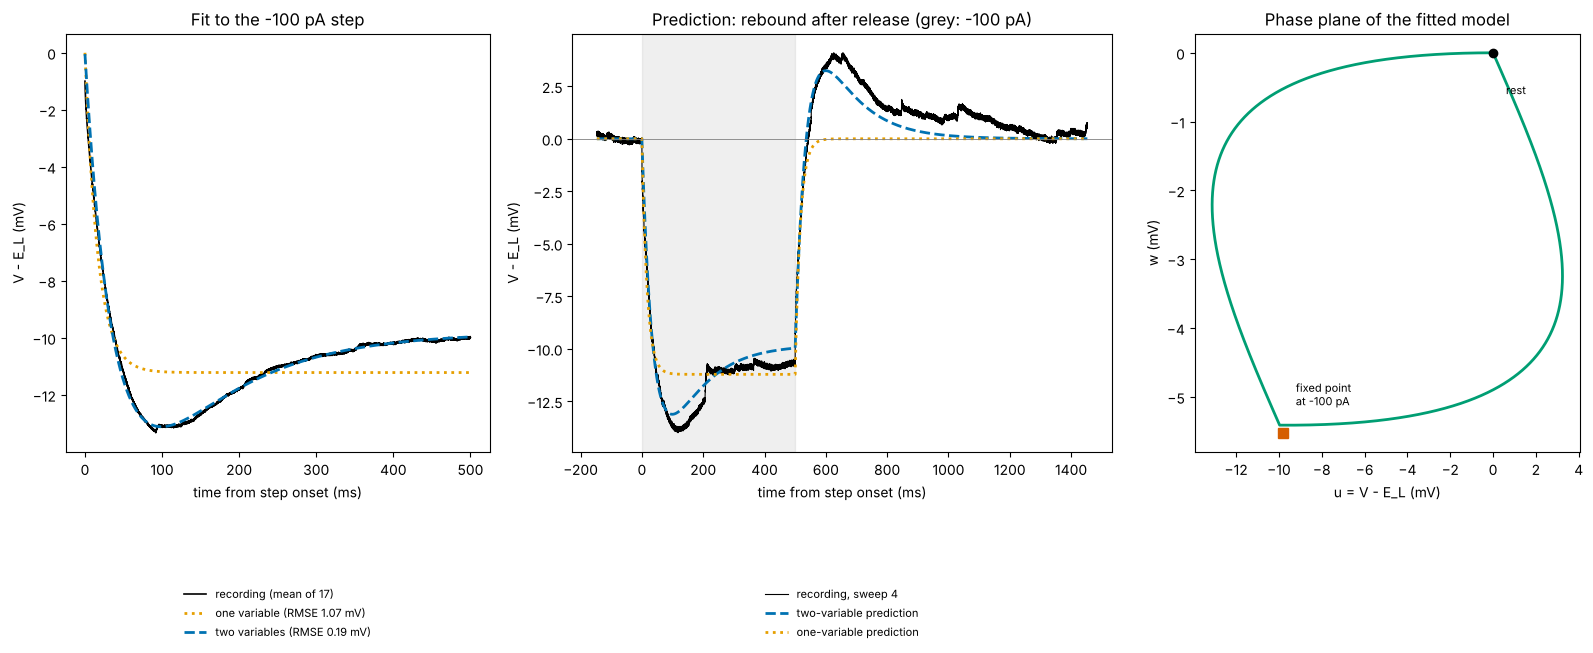

In [11]:
# Out-of-sample prediction: sweep 4 (0 pA after the -100 pA step). The one-variable model predicts a monotone return to rest.
s4 = 4
seg = slice(int(1.0 * fs), int(2.6 * fs))
u4 = V[s4, seg] - V[s4, int(1.0 * fs):a].mean()                             # (16000,) mV
I4 = I[s4, seg]
u4_2 = simulate_sag(p_hat, I4)
x1, u4_1 = 0.0, np.empty(len(I4))
for k, Ik in enumerate(I4):                                                   # one-variable model, exact update
    x1 = fit1.x[1] * Ik + (x1 - fit1.x[1] * Ik) * np.exp(-0.1 / fit1.x[0]); u4_1[k] = x1
t4 = np.arange(len(u4)) / fs * 1000 - (a - int(1.0 * fs)) / fs * 1000       # ms from onset of the -100 pA step
after = (t4 >= 550) & (t4 < 650)
print(f"100-200 ms after release: data {u4[after].mean():+.2f} mV, two-variable model {u4_2[after].mean():+.2f} mV, one-variable model {u4_1[after].mean():+.2f} mV")
print(f"peak rebound after release: data {u4[t4 > 500].max():+.2f} mV (single sweep), two-variable model {u4_2[t4 > 500].max():+.2f} mV")

fig, axes = plt.subplots(1, 3, figsize=(16, 7), gridspec_kw=dict(width_ratios=[1.1, 1.4, 1]))
ax = axes[0]
ax.plot(t_ms, u_obs, color='black', lw=1.2, label='recording (mean of 17)')
ax.plot(t_ms, fit1.x[1] * -100 * (1 - np.exp(-t_ms / fit1.x[0])), ':', color=PALETTE[4], lw=2, label=f'one variable (RMSE {rmse1:.2f} mV)')
ax.plot(t_ms, simulate_sag(p_hat, I_on), '--', color=PALETTE[0], lw=2, label=f'two variables (RMSE {rmse2:.2f} mV)')
ax.set_xlabel('time from step onset (ms)'); ax.set_ylabel('V - E_L (mV)'); ax.set_title('Fit to the -100 pA step')
ax.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=1)
ax = axes[1]
ax.plot(t4, u4, color='black', lw=0.8, label='recording, sweep 4')
ax.plot(t4, u4_2, '--', color=PALETTE[0], lw=2, label='two-variable prediction')
ax.plot(t4, u4_1, ':', color=PALETTE[4], lw=2, label='one-variable prediction')
ax.axvspan(0, 500, color='grey', alpha=0.12); ax.axhline(0, color='grey', lw=0.6)
ax.set_xlabel('time from step onset (ms)'); ax.set_ylabel('V - E_L (mV)'); ax.set_title('Prediction: rebound after release (grey: -100 pA)')
ax.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=1)
ax = axes[2]
x_tr = np.zeros(2); traj = []
J_ = J_hat; M_ = expm(J_ * 0.1)
for Ik in I4:
    x_star = -np.linalg.solve(J_, np.array([p_hat[1] * Ik / p_hat[0], 0.0])); x_tr = x_star + M_ @ (x_tr - x_star); traj.append(x_tr.copy())
traj = np.array(traj)
ax.plot(traj[:, 0], traj[:, 1], color=PALETTE[2], lw=2)
ax.plot(0, 0, 'o', color='black', ms=6); ax.annotate('rest', (0, 0), (0.6, -0.6), fontsize=8)
st = -np.linalg.solve(J_, np.array([p_hat[1] * -100 / p_hat[0], 0.0])); ax.plot(*st, 's', color=PALETTE[1], ms=7); ax.annotate('fixed point\nat -100 pA', st, (st[0] + 0.6, st[1] + 0.4), fontsize=8)
ax.set_xlabel('u = V - E_L (mV)'); ax.set_ylabel('w (mV)'); ax.set_title('Phase plane of the fitted model')
plt.tight_layout(); plt.show()

**Reading the mini-lab.**
- **Fit.** Two variables describe the step response five times better than one (RMSE about 0.2 against 1.1 mV, against a recording noise of a few tenths of a millivolt). The fitted $\tau_m \approx 34$ ms and $R_m \approx 150$ MΩ agree with Lesson 21's early-window fit, which is reassuring: the early fit was seeing the membrane before the sag acted. The slow variable has $\tau_w \approx 210$ ms and coupling $g \approx 0.56$.
- **Eigenvalues.** Both are real and negative (timescales of about 39 and 116 ms): a **stable node**. The neuron overshoots (the sag) but does not ring. The trace–determinant test says it would become a resonator (a stable focus) only if the coupling were about twice as strong ($g > 1.1$); some neurons with strong $I_h$ do show such subthreshold resonance, at a few hertz.
- **Prediction.** After the current is switched off, the slow variable is still negative and keeps depolarising the cell, so the model predicts a **rebound above rest** of about 3 mV, decaying over a few hundred milliseconds. Sweep 4, which was not used in the fit, shows exactly that (+3.2 mV on average 100–200 ms after release, against +2.9 mV predicted), while the one-variable model can only return to rest. The two-variable model slightly underestimates the late tail.
- **What the phase plane shows.** During the step the state moves from rest towards the new fixed point, first mostly along $u$ (fast) and then along $w$ (slow); after release it loops back to rest the other way round. The loop is the sag and the rebound.

**Limitations.** One neuron, a linear model of a nonlinear current (the real $I_h$ depends on voltage, so $g$ and $\tau_w$ would change with the step size), a single sweep for the out-of-sample test, and no correction for electrode artefacts. The model is a linearisation of a Hodgkin–Huxley-type system around rest, which is exactly what Part 3 says such a linearisation should be good for: small deviations.

# **Part 6: Applications in Neuroscience and Machine Learning**

| Idea | Neuroscience | Machine learning |
|---|---|---|
| State vectors, coupled ODEs | Hodgkin–Huxley and reduced models (FitzHugh–Nagumo, Izhikevich); adaptation; synaptic dynamics | continuous-time RNNs; neural ODEs; state-space models (S4, Mamba) |
| Phase plane, nullclines | excitability classes; analysis of 2D neuron models | visualising low-dimensional dynamics learned by RNNs |
| Fixed points, basins | attractor networks for working memory, decisions and head direction; Hopfield networks | fixed-point analysis of trained RNNs (finding "line attractors" and "slow points") |
| Jacobian and eigenvalues | stability of network states; subthreshold resonance | exploding and vanishing gradients (eigenvalues of recurrent Jacobians, Lesson 10); stable training of RNNs |
| Wilson–Cowan, E–I balance | cortical oscillations (gamma, PING), epilepsy models, neural mass models for EEG/MEG | inhibition-like normalisation; E–I constrained networks |
| Bifurcations | onset of oscillations and seizures; transitions between brain states | sudden changes in training dynamics; edge-of-chaos initialisation |

# **Part 7: Summary, Exit Ticket and Project Week**

| Idea | Formula / code | What to remember |
|---|---|---|
| Coupled ODEs | $\dot{\mathbf x} = \mathbf F(\mathbf x, t)$ | one vector equation; Euler and `solve_ivp` work unchanged |
| Linear systems | $\dot{\mathbf x} = A\mathbf x + \mathbf b$; modes $e^{\lambda_i t}\mathbf v_i$ | eigenvalues give timescales; complex pairs give oscillation |
| Phase plane | direction field; $\dot x = 0$ and $\dot y = 0$ nullclines | fixed points at nullcline intersections; basins separated by saddles |
| Jacobian | $J_{ij} = \partial F_i/\partial x_j$ at $\mathbf x^*$ | linearisation: $\dot{\boldsymbol\delta} = J\boldsymbol\delta$ near the fixed point |
| Trace–determinant | $\lambda^2 - \tau\lambda + \Delta = 0$ | $\Delta < 0$ saddle; $\tau < 0$ stable; $\tau^2 < 4\Delta$ oscillatory |
| Wilson–Cowan | $\tau_E\dot r_E = -r_E + F_E(\cdot)$, $\tau_I\dot r_I = -r_I + F_I(\cdot)$ | bistability from recurrent excitation; oscillations from delayed inhibition |
| Bifurcation | eigenvalues crossing zero as a parameter changes | qualitative change: fixed points appear, or oscillations begin |

**Exit ticket.** A fixed point has Jacobian $J = \begin{pmatrix} -0.2 & -1 \\ 0.8 & -0.1\end{pmatrix}$ (1/ms). (a) Compute the trace and determinant and classify it. (b) What is the period of the oscillation, approximately? (c) Which single entry would you change, and in which direction, to make it unstable?

*(Answers: (a) $\tau = -0.3$, $\Delta = 0.02 + 0.8 = 0.82$; $\tau^2 = 0.09 < 4\Delta = 3.28$, so a stable focus. (b) $\lambda = -0.15 \pm i\sqrt{0.82 - 0.0225} \approx -0.15 \pm 0.893i$, so period $2\pi/0.893 \approx 7$ ms. (c) Make the trace positive while keeping $\Delta > 0$: for example raise $J_{11}$ (stronger self-excitation) from −0.2 to above +0.1.)*

**The course so far, in one model.** The Wilson–Cowan equations use vectors and weighted sums (Weeks 1–2), sigmoids, derivatives and Jacobians (Weeks 3–4), noisy thresholds and population averages (Week 5), and relaxation dynamics (Week 6). **Project week** asks you to combine these on a question of your own, using the datasets of the course (the Steinmetz sessions and the patch-clamp recordings) or one you bring.

**Further reading.** S. H. Strogatz, *Nonlinear Dynamics and Chaos* (2nd ed., 2015), Chapters 5–8; W. Gerstner, W. M. Kistler, R. Naud and L. Paninski, *Neuronal Dynamics* (2014), Chapters 4, 6 and 16 (free online); H. R. Wilson and J. D. Cowan, "Excitatory and inhibitory interactions in localized populations of model neurons", *Biophysical Journal* 12 (1972); E. M. Izhikevich, *Dynamical Systems in Neuroscience* (2007), Chapters 1 and 4; the Neuromatch Academy tutorials on dynamical systems and the Wilson–Cowan model (W2D2, W2D4), CC-BY.